In [22]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import fashion_mnist
from tensorflow import keras
import matplotlib.pyplot as plt



In [12]:
(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

# Create one fixed, stratified train/validation split for all comparisons
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full,
)

In [13]:
# Normalize pixels to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(f"Train: {x_train.shape}, validation: {x_val.shape}")

Train: (48000, 28, 28), validation: (12000, 28, 28)


In [14]:
model = keras.Sequential(
    [
        #1) input layer
        keras.Input(shape=(28,28)),
        keras.layers.Flatten(),
        #2) hidden layers
                      #Dense(num_of_Neuron , activation_function )
        keras.layers.Dense(32, activation="relu"),  # HL1

        #3) output layer (Dense عادي ولكن الاخيرة )
              # num_of_Neuron = num of classes
         keras.layers.Dense(10,activation="softmax"), #softmax give you ten porb.

    ]


)

In [15]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    )

In [16]:
#Model training
history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_data=(x_val, y_val),
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8004 - loss: 0.5768 - val_accuracy: 0.8401 - val_loss: 0.4590
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8465 - loss: 0.4351 - val_accuracy: 0.8322 - val_loss: 0.4567
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 936us/step - accuracy: 0.8564 - loss: 0.4021 - val_accuracy: 0.8716 - val_loss: 0.3786
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 971us/step - accuracy: 0.8661 - loss: 0.3752 - val_accuracy: 0.8500 - val_loss: 0.4148
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8711 - loss: 0.3630 - val_accuracy: 0.8744 - val_loss: 0.3597
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8757 - loss: 0.3463 - val_accuracy: 0.8724 - val_loss: 0.3685
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8785 - loss: 0.3341 - val_accuracy: 0.8717 - val_loss: 0.3646
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8825 - loss: 0.326

# Task 1

In [30]:
# 1
print(f"training data shape: {x_train.shape}, test data shape: {y_test.shape}")

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]
#2,4

print(f"The class names are: {class_names}")
print(f"The number of samples for each class: {np.unique(y_train, return_counts=True)[1]}")

training data shape: (48000, 28, 28), test data shape: (10000,)
The class names are: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
The number of samples for each class: [4800 4800 4800 4800 4800 4800 4800 4800 4800 4800]


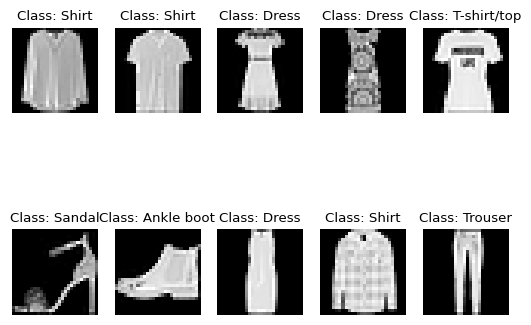

In [29]:
#3
for i in range(10):

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Class: {class_names[y_train[i]]}")
    plt.axis("off")



- We normalize the pixel values to ensure uniform feature weighting and speed up optimization.
- The dataset is balanced as each class has an equal amount of samples.

# Task 2

In [31]:
model.predict(x_test)
metrics = model.evaluate(x_test, y_test, verbose=0)
test_accuracy = metrics[1]
print(f"Test accuracy: {test_accuracy:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step
Test accuracy: 0.8587


Training accuracy: 0.8881
Validation accuracy: 0.8783
Test accuracy: 0.8587


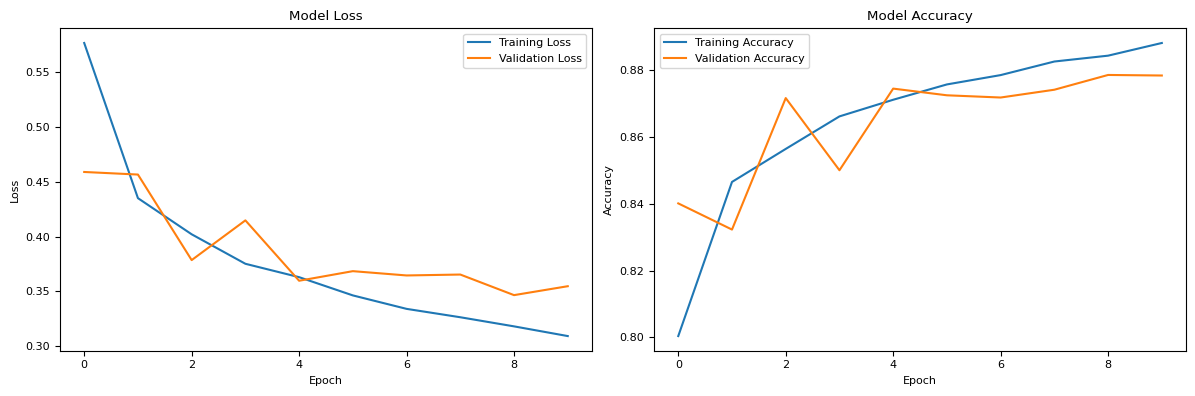

In [33]:
print(f"Training accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"Validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


- Flatten: changes the spatial shape of your data from a multidimensional matrix into a single, long vector.
- ReLU: is an activation function that introduces non-linearity to the model, allowing the neural network to learn complex, non-linear relationships.
- The Softmax layer: acts as the final output function that turns raw network scores into clean probabilities that add up to 1.0 (100%).

# Task 3

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step


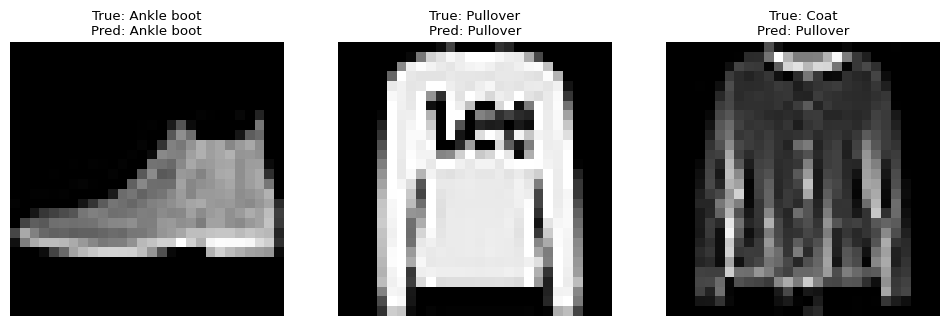

In [43]:
#Select 3 test images: at least one correct and one incorrect prediction.
test_predictions = model.predict(x_test)
img1 = 0  # Correct prediction
img2 = 1  # Correct prediction

predicted_classes = np.argmax(test_predictions, axis=1)
incorrect_indices = np.flatnonzero(predicted_classes != y_test)

if len(incorrect_indices) == 0:
    raise ValueError("No incorrect predictions found.")

img3 = int(incorrect_indices[0])


plt.figure(figsize=(12, 4))
for i, img_idx in enumerate([img1, img2, img3]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_test[img_idx], cmap="gray")
    plt.title(f"True: {class_names[y_test[img_idx]]}\nPred: {class_names[np.argmax(test_predictions[img_idx])]}")
    plt.axis("off")




- as shown the model predicted a Pullover mistaking it for a coat, 